# Value at Risk and Expected Shortfall of a ₹1 crore multi-asset ETF portfolio

This notebook measures the one-day and ten-day market risk of a ₹1 crore (₹1,00,00,000) portfolio of six NSE-listed ETFs at the close of **Friday 30-Oct-2026**. It uses five years of daily prices (1-Nov-2021 to 30-Oct-2026, 1,240 trading days) and compares three families of methods:

1. **Historical simulation**: re-use the actual daily returns of the past.
2. **Parametric (variance-covariance)**: assume a distribution (normal, or normal adjusted for skewness and fat tails with the Cornish-Fisher expansion) and use its formula.
3. **Monte Carlo**: simulate 100,000 days from a fitted multivariate normal or Student-t distribution (seed 42).

It then tests the models out of sample with a rolling 250-day backtest (Kupiec, Christoffersen and the Basel traffic light), splits the risk by ETF (component VaR), and runs stress tests.

Every number comes from the functions in `src/`, the same ones that `python src/run_all.py` uses. The notebook reads only the saved files in `data/` and writes nothing. The last section runs the validation checks and confirms that the results equal the CSV files in `outputs/`.

**Conventions.** Returns are simple daily returns. VaR and ES are reported as positive rupee losses. For a confidence level $\alpha$ (95% or 99%) and tail probability $p = 1-\alpha$:

$$\text{VaR}_\alpha = -Q_p(r)\,V, \qquad \text{ES}_\alpha = -\mathbb{E}\left[r \mid r \le Q_p(r)\right] V$$

where $Q_p$ is the $p$-quantile of the daily portfolio return $r$ and $V$ = ₹1 crore. In words: on 99 days out of 100 the loss should not exceed the 99% VaR, and ES is the average loss on the remaining worst 1% of days. ₹1 lakh = ₹1,00,000 = 1% of the portfolio.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import analysis as an, backtest as bt, config as cfg, data_prep as dp, plots, var_models as vm

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
V = cfg.PORTFOLIO_VALUE
LAKH = 1e5
print(f"Portfolio value Rs {an.inr(V)} | valuation date {cfg.VALUATION_DATE} | "
      f"window {cfg.WINDOW_START} to {cfg.WINDOW_END} | {cfg.N_SIMULATIONS:,} simulations, seed {cfg.SEED}")

Portfolio value Rs 1,00,00,000 | valuation date 2026-10-30 | window 2021-11-01 to 2026-10-30 | 100,000 simulations, seed 42


## 1. The portfolio

Six ETFs, no single stocks, spread across five asset classes. ETFs keep this project separate from the company-level projects in the portfolio, and each ETF tracks a published index, so the risk can be traced to a market rather than to one firm.

| ETF | Index or asset | Weight | Role |
|---|---|---:|---|
| NIFTYBEES | NIFTY 50 | 30% | core Indian large-cap equity |
| JUNIORBEES | NIFTY Next 50 | 10% | the next 50 large companies (more cyclical) |
| BANKBEES | NIFTY Bank | 10% | banks, the largest sector in the Indian market |
| MON100 | Nasdaq-100, in rupees | 10% | US technology; also carries USD/INR currency risk |
| GOLDBEES | physical gold | 15% | a traditional hedge in equity sell-offs |
| SETF10GILT | NIFTY 10-year benchmark G-Sec | 25% | long-duration government bond |

The bond ETF was chosen from nine candidates by a fixed rule (section 2). Positions are valued at the 30-Oct-2026 closing prices.

In [2]:
inp = an.load_inputs()
h = inp.holdings.copy()
h["value_inr"] = h["value_inr"].map(an.inr)
h["weight"] = (100 * h["weight"]).map("{:.0f}%".format)
h["units"] = h["units"].round(1)
display(h)

,ticker,label,fund,asset_class,weight,value_inr,price_inr,units
0,NIFTYBEES.NS,NIFTYBEES,Nippon India ETF Nifty 50 BeES,Indian large-cap equity,30%,"30,00,000",262.89,11411.6
1,JUNIORBEES.NS,JUNIORBEES,Nippon India ETF Nifty Next 50 Junior BeES,Indian large/mid-cap equity,10%,"10,00,000",730.90,1368.2
2,BANKBEES.NS,BANKBEES,Nippon India ETF Nifty Bank BeES,Indian bank equity,10%,"10,00,000",565.47,1768.4
3,MON100.NS,MON100,Motilal Oswal Nasdaq 100 ETF,"US equity (INR, unhedged)",10%,"10,00,000",284.94,3509.5
4,GOLDBEES.NS,GOLDBEES,Nippon India ETF Gold BeES,Gold,15%,"15,00,000",115.23,13017.4
5,SETF10GILT.NS,SETF10GILT,SBI Nifty 10 yr Benchmark G-Sec ETF,Indian government bond (10-year),25%,"25,00,000",258.85,9658.1


## 2. Data: sources and cleaning

**Sources.** Daily prices come from Yahoo Finance through `yfinance` (`auto_adjust=False`; the `Adj Close` column equals `Close` because none of the six ETFs paid a distribution in the period). Yahoo's data for Indian ETFs has holes, so every suspicious row is checked against the **official NSE bhavcopy** (the exchange's daily closing-price file). `src/fetch_data.py` downloaded both on 31-Oct-2026; everything below runs offline from `data/raw/`.

**Calendar.** A day is a trading day if the NIFTY 50 index (`^NSEI`) has a close on Yahoo. For every other date in the window the NSE bhavcopy was requested: a file exists only if the exchange held a session. That found five sessions Yahoo omits entirely (the Diwali Muhurat session on Sunday 12-Nov-2023, three Saturday sessions in 2024 and the Sunday Union Budget session of 1-Feb-2026). One Yahoo row with no index close and zero volume in every ETF (15-Jan-2026, a market holiday) is dropped.

**Fixes.** A Yahoo row is replaced with the NSE close when the two differ by more than 0.01%; most such rows are zero-volume placeholders that Yahoo fills with a stale or wrong price. Missing rows are inserted from the bhavcopy.

In [3]:
raw = dp.load_raw(list(dict.fromkeys(cfg.TICKERS + list(cfg.BOND_CANDIDATES) + [cfg.CALENDAR_TICKER])))
nse = dp.read_nse_closes()
calendar, cal_notes = dp.trading_calendar(raw, dp.read_nse_requests())
yahoo_calendar, _ = dp.trading_calendar(raw)
clean, fixes = dp.clean_portfolio_prices(raw, nse, calendar)
clean = clean[clean.index <= pd.Timestamp(cfg.WINDOW_END)]
fixes_df = pd.DataFrame(cal_notes + fixes)
print("Data fixes by type:")
print(fixes_df.groupby("action").size().to_string())
same_file = np.allclose(clean.round(4).reindex(inp.prices.index).to_numpy(), inp.prices.to_numpy(), rtol=0, atol=1e-9)
print(f"\n{'PASS' if same_file else 'FAIL'}: data/prices_adjclose.csv equals the prices rebuilt from data/raw "
      f"({len(inp.prices)} rows x {inp.prices.shape[1]} ETFs)")
print("\nCloses replaced because Yahoo differed from the NSE close:")
display(fixes_df[fixes_df["action"] == "close replaced"][["date", "ticker", "reason"]])

Data fixes by type:
action
close replaced    19
row dropped        1
row inserted      35
session added      5

PASS: data/prices_adjclose.csv equals the prices rebuilt from data/raw (1260 rows x 6 ETFs)

Closes replaced because Yahoo differed from the NSE close:


,date,ticker,reason
10,2024-11-01,NIFTYBEES.NS,"Yahoo bad print with zero volume 270.64; NSE bhavcopy close 272.37 (volume 1,875,788), difference -0.64%"
11,2025-03-18,NIFTYBEES.NS,"Yahoo bad print with zero volume 252.18; NSE bhavcopy close 255.82 (volume 7,134,763), difference -1.42%"
18,2024-11-01,JUNIORBEES.NS,"Yahoo bad print with zero volume 746.59; NSE bhavcopy close 756.06 (volume 101,799), difference -1.25%"
19,2025-03-18,JUNIORBEES.NS,"Yahoo bad print with zero volume 635.54; NSE bhavcopy close 652.43 (volume 562,657), difference -2.59%"
21,2025-12-19,JUNIORBEES.NS,"Yahoo bad print with zero volume 734.83; NSE bhavcopy close 734.34 (volume 207,344), difference +0.07%"
27,2024-11-01,BANKBEES.NS,"Yahoo bad print with zero volume 529.64; NSE bhavcopy close 530.44 (volume 162,586), difference -0.15%"
28,2025-03-18,BANKBEES.NS,"Yahoo bad print with zero volume 495.86; NSE bhavcopy close 506.31 (volume 1,566,346), difference -2.06%"
30,2025-12-19,BANKBEES.NS,"Yahoo bad print with zero volume 609.71; NSE bhavcopy close 609.42 (volume 266,711), difference +0.05%"
32,2022-09-12,MON100.NS,"Yahoo bad print with zero volume 97.29; NSE bhavcopy close 98.72 (volume 455,487), difference -1.45%"
34,2024-01-15,MON100.NS,"Yahoo bad print with zero volume 135.74; NSE bhavcopy close 136.08 (volume 237,155), difference -0.25%"


**Cross-check against NSE.** 76 dates were fetched from NSE: the calendar check, every date with a missing, zero-volume or extreme Yahoo row, the valuation date, the election-results days of June 2024 and a random sample of 25 ordinary days (seed 42). After cleaning, every one of them matches the exchange's close and previous close. On the random sample Yahoo was already right, which suggests the remaining unchecked days are reliable too.

In [4]:
cross = dp.nse_crosscheck(raw, inp.prices, nse)
summary_cross = cross.groupby("purpose")[["yahoo_match", "clean_match", "prev_match"]].agg(["sum", "count"])
display(summary_cross)

yahoo_match       clean_match       prev_match      
                       sum count         sum count        sum count
purpose                                                            
calendar_check           0    30          30    30         30    30
random_sample          144   144         144   144        144   144
verification           255   279         279   279        279   279

**Jump screen.** One-day moves above 8% (equity ETFs) or 3% (gold and bond ETFs) are listed below. A move counts as *genuine* when both the close and the previous close equal the NSE bhavcopy. The two large MON100 moves in October 2025 were a Yahoo bad print (−9.6% and +12.9%) that disappears after the fix. The gold ETF's −9.5% on 2-Feb-2026 in the raw data covered two sessions; with the Sunday 1-Feb-2026 session inserted it splits into −6.7% and −3.0%. Every other large gold move is real: gold had a violent January to March 2026, including a 10.5% fall on 30-Jan-2026.

In [5]:
jumps = dp.jump_screen(raw, inp.prices, nse, calendar)
print(jumps["status"].str.split(":").str[0].value_counts().to_string())
display(jumps[["date", "ticker", "raw_return_pct", "clean_return_pct", "nse_close", "nse_prev_close", "status"]])

status
genuine     32
artefact     3


,date,ticker,raw_return_pct,clean_return_pct,nse_close,nse_prev_close,status
0,2025-10-24,MON100.NS,-9.62,0.56,241.80,240.46,artefact: within threshold after the data fix (bad print or missing session)
1,2025-10-27,MON100.NS,12.87,1.44,245.29,241.80,artefact: within threshold after the data fix (bad print or missing session)
2,2022-02-24,GOLDBEES.NS,3.55,3.55,44.62,43.09,genuine: close and previous close match NSE bhavcopy
3,2022-03-07,GOLDBEES.NS,3.02,3.02,46.00,44.65,genuine: close and previous close match NSE bhavcopy
4,2024-04-01,GOLDBEES.NS,3.02,3.02,58.32,56.61,genuine: close and previous close match NSE bhavcopy
5,2024-07-23,GOLDBEES.NS,-3.09,-3.09,60.16,62.08,genuine: close and previous close match NSE bhavcopy
6,2025-04-01,GOLDBEES.NS,3.45,3.45,76.72,74.16,genuine: close and previous close match NSE bhavcopy
7,2025-04-11,GOLDBEES.NS,4.02,4.02,77.90,74.89,genuine: close and previous close match NSE bhavcopy
8,2025-04-23,GOLDBEES.NS,-3.03,-3.03,80.39,82.90,genuine: close and previous close match NSE bhavcopy
9,2025-05-06,GOLDBEES.NS,3.20,3.20,82.13,79.58,genuine: close and previous close match NSE bhavcopy


**Choosing the bond ETF.** The 25% bond sleeve should hold long-duration government bonds. Nine bond ETFs were screened on the same five-year window. Rule: holds G-Secs, at least 4.9 years of history, at most 5 missing days and at most 5% stale days (a close equal to the previous close, a sign of thin trading); among those, the lowest stale share. Only **SETF10GILT** (SBI Nifty 10 yr Benchmark G-Sec ETF) passes. The more liquid LTGILTBEES fails on 21 missing days and 9.1% stale days.

In [6]:
names = json.loads((cfg.RAW / "download_log.json").read_text(encoding="utf-8"))["names"]
screen = dp.bond_screen(raw, yahoo_calendar, names)
display(screen[["ticker", "name", "holds", "years_in_window", "gap_days", "stale_pct", "zero_volume_pct",
                "median_traded_value_lakh", "ann_vol_pct", "lag1_autocorr", "eligible", "selected"]])

,ticker,name,holds,years_in_window,gap_days,stale_pct,zero_volume_pct,median_traded_value_lakh,ann_vol_pct,lag1_autocorr,eligible,selected
0,LTGILTBEES.NS,Nippon India Mutual Fund - Nippon India ETF Nifty 8-13 yr G-Sec Long Term Gilt,"G-Secs, Nifty 8-13 yr G-Sec index",5.00,21,9.14,0.08,305.3,4.68,-0.166,False,False
1,SETF10GILT.NS,SBI Nifty 10 yr Benchmark G-Sec ETF,"G-Secs, Nifty 10 yr Benchmark G-Sec index",5.00,1,2.43,0.65,14.4,5.45,-0.288,True,True
2,GILT5YBEES.NS,Nippon India ETF Nifty 5 Yr Benchmark G-Sec,"G-Secs, Nifty 5 yr Benchmark G-Sec index",5.00,4,5.12,10.48,112.9,3.14,-0.156,False,False
3,EBBETF0433.NS,BHARAT Bond ETF - April 2033,"AAA PSU bonds, target maturity Apr-2033",1.66,3,0.25,0.25,50.9,3.83,-0.309,False,False
4,EBBETF0430.NS,BHARAT Bond ETF April 2030,"AAA PSU bonds, target maturity Apr-2030",5.00,1,0.24,0.24,139.7,3.08,-0.172,False,False
5,EBBETF0431.NS,"Edelweiss Amc Ltd - Edelweiss Mutual Fund - Edelweiss Bharat Bond Exchange Traded Fund, April 2031","AAA PSU bonds, target maturity Apr-2031",5.00,21,0.16,0.08,95.9,3.08,-0.150,False,False
6,LICNETFGSC.NS,LIC MF Nifty 8-13 yr G-SEC ETF,G-Secs (long term),5.00,1,6.65,0.24,5.0,9.64,-0.401,False,False
7,GSEC10IETF.NS,ICICI Prudential Nifty 10 yr Benchmark G-Sec ETF,"G-Secs, 10-year benchmark",1.74,3,9.18,5.41,1.5,6.93,-0.272,False,False
8,GSEC10ABSL.NS,Aditya BSL CRISIL 10 Year Gilt ETF,"G-Secs, 10-year",1.66,3,32.02,27.83,0.0,8.49,-0.315,False,False


## 3. Returns, volatility and correlation

Daily simple returns $r_{i,t} = P_{i,t}/P_{i,t-1} - 1$. The portfolio return is $r_{p,t} = \sum_i w_i r_{i,t}$, which assumes the weights are reset to target every day (constant weights). Over one day that is exact for today's positions, and it lets every past day be read as "what would today's portfolio have done on that day".

In [7]:
stats_tab = an.asset_stats(inp)
display(stats_tab)
corr_full, corr_recent = an.correlations(inp)
display(corr_full.round(2))

,series,cagr_pct,ann_vol_pct,daily_mean_pct,skew,excess_kurtosis,worst_day_pct,worst_day,best_day_pct,best_day
0,NIFTYBEES,6.58,12.61,0.0289,-0.124,2.17,-3.62,2022-02-24,3.90,2026-04-08
1,JUNIORBEES,10.64,16.51,0.0463,-0.571,2.04,-5.26,2022-02-24,4.80,2026-04-08
2,BANKBEES,7.46,15.56,0.0339,-0.111,3.24,-4.68,2022-02-24,5.84,2026-04-08
3,MON100,19.74,21.50,0.0819,-0.023,2.29,-6.59,2025-04-07,5.85,2026-04-15
4,GOLDBEES,22.65,18.20,0.0890,-0.657,15.22,-10.52,2026-01-30,7.89,2026-01-29
5,SETF10GILT,4.93,5.43,0.0200,0.018,6.02,-1.71,2022-01-20,2.26,2022-02-07
6,Portfolio,10.88,8.79,0.0432,-0.316,3.35,-3.30,2026-03-23,3.20,2026-04-08


,NIFTYBEES,JUNIORBEES,BANKBEES,MON100,GOLDBEES,SETF10GILT
NIFTYBEES,1.00,0.80,0.87,0.43,0.10,0.14
JUNIORBEES,0.80,1.00,0.70,0.42,0.11,0.11
BANKBEES,0.87,0.70,1.00,0.34,0.08,0.14
MON100,0.43,0.42,0.34,1.00,0.11,0.07
GOLDBEES,0.10,0.11,0.08,0.11,1.00,0.02
SETF10GILT,0.14,0.11,0.14,0.07,0.02,1.00


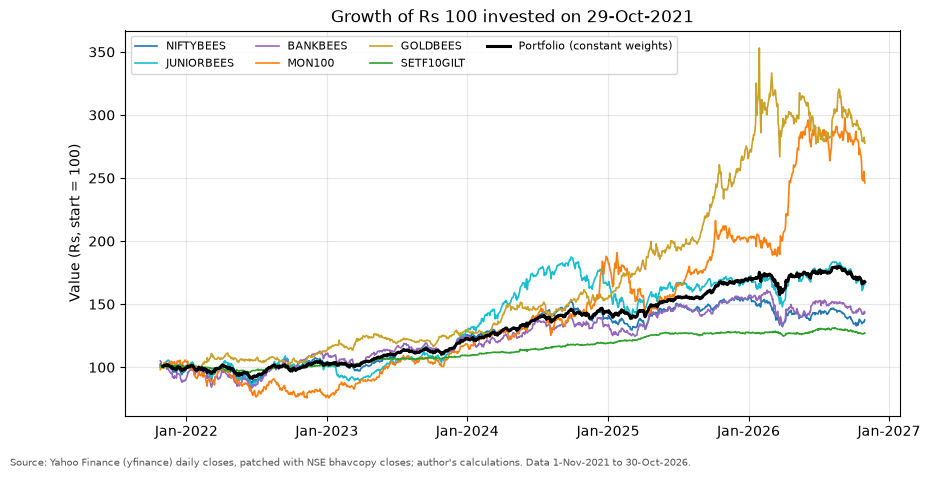

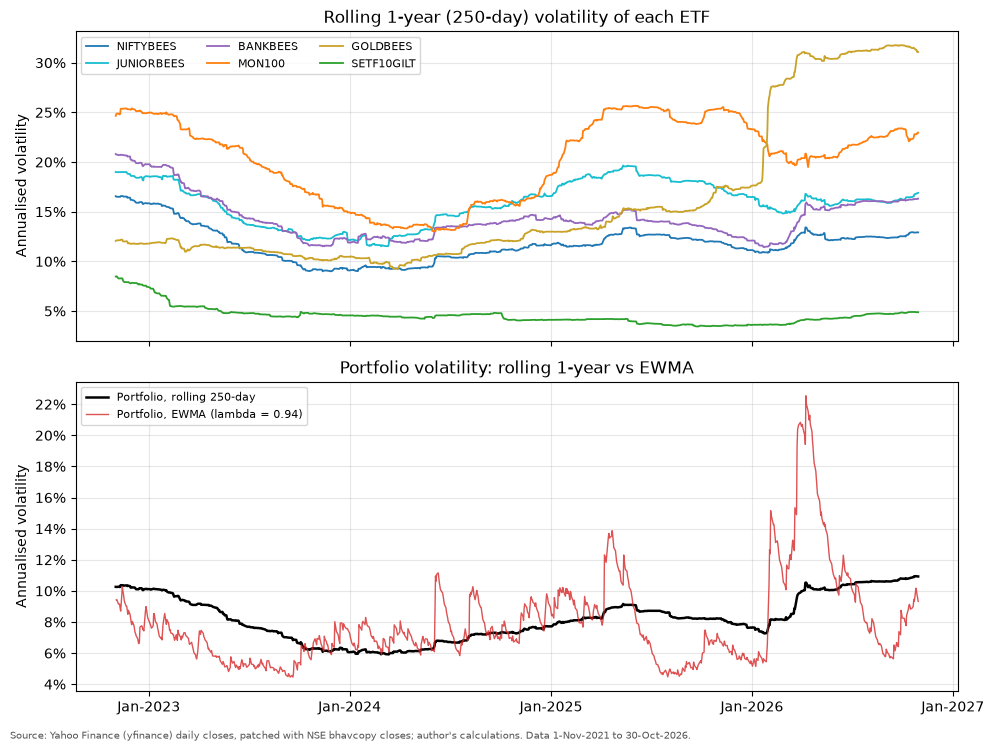

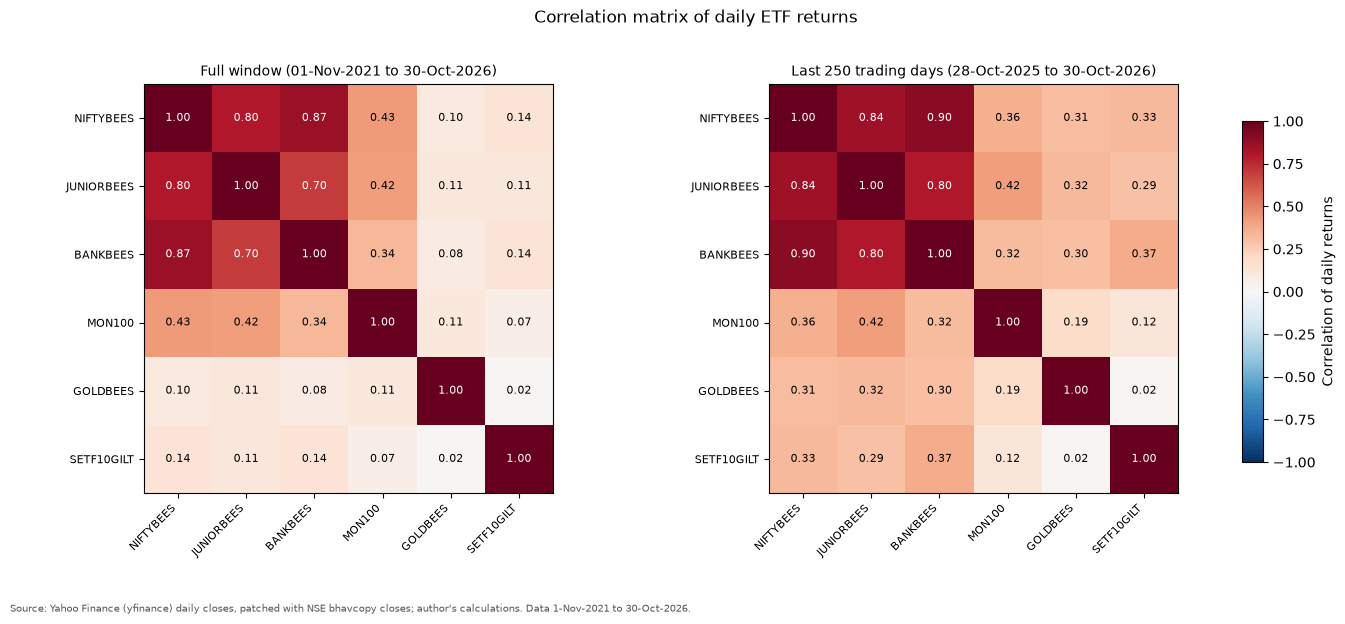

In [8]:
sigma_ewma = bt.ewma_sigma_forecasts(inp.returns, inp.w, cfg.EWMA_LAMBDA, cfg.RECENT_WINDOW)
plots.plot_growth(inp.prices, inp.port); plt.show()
plots.plot_rolling_vol(inp.returns, inp.port, sigma_ewma.iloc[cfg.RECENT_WINDOW:]); plt.show()
plots.plot_correlation(corr_full, corr_recent,
                       (f"Full window ({inp.returns.index[0]:%d-%b-%Y} to {inp.returns.index[-1]:%d-%b-%Y})",
                        f"Last 250 trading days ({inp.returns.index[-cfg.RECENT_WINDOW]:%d-%b-%Y} to "
                        f"{inp.returns.index[-1]:%d-%b-%Y})")); plt.show()

The portfolio's annual volatility (about 8.8%) is far below that of any equity ETF because gold and the gilt ETF have low correlation with Indian equities (about 0.1 over five years). In the last 250 days those correlations rose to about 0.3, so the hedge was weaker exactly when volatility was highest. The portfolio's daily returns are fat-tailed (excess kurtosis about 3.4) and slightly left-skewed, which is why the normal distribution will understate the 99% tail.

## 4. One-day VaR and ES at the 30-Oct-2026 close

**Historical simulation.** The 1,240 daily portfolio returns of the window (and, separately, the last 250) are the scenarios. VaR is the empirical $p$-quantile with linear interpolation (`numpy.quantile` default). ES is the mean of the returns at or below it: 13 days at 99% and 62 days at 95% in the full window; 3 and 13 days in the last 250.

**Parametric normal.** With zero mean and portfolio volatility $\sigma_p = \sqrt{w^\top \Sigma w}$:

$$\text{VaR} = z_\alpha \sigma_p V, \qquad \text{ES} = \frac{\varphi(z_\alpha)}{1-\alpha}\,\sigma_p V$$

with $z_{0.95} = 1.645$, $z_{0.99} = 2.326$. $\Sigma$ is either the sample covariance of the full window or the RiskMetrics EWMA forecast for the next day, $\Sigma_{t+1} = \lambda \Sigma_t + (1-\lambda) r_t r_t^\top$ with $\lambda = 0.94$, which weights recent days more.

**Cornish-Fisher (modified VaR).** The normal quantile is adjusted for sample skewness $S$ and excess kurtosis $K$:

$$z_{cf} = z + \frac{(z^2-1)S}{6} + \frac{(z^3-3z)K}{24} - \frac{(2z^3-5z)S^2}{36}, \quad z = \Phi^{-1}(p)$$

VaR $= -z_{cf}\,\sigma_p V$. ES is the average of the Cornish-Fisher quantile over the tail, $-\frac{\sigma_p V}{p}\int_0^p z_{cf}(\Phi^{-1}(u))\,du$, which has a closed form because $z_{cf}$ is a cubic in $z$ (checked against numerical integration in section 11).

**Monte Carlo.** 100,000 draws of the six-ETF return vector, seed 42. Normal: $r = Lz$ with $LL^\top = \Sigma$ (Cholesky). Student-t: $r = L_s z \sqrt{\nu/W}$, $W \sim \chi^2_\nu$, with the scale matrix set so that the covariance is still $\Sigma$; the degrees of freedom $\nu$ are fitted by maximum likelihood to the standardised portfolio returns. VaR and ES are then read from the simulated P&L exactly as in historical simulation.

In [9]:
od = an.one_day_var(inp)
print(f"sigma_p (sample) = {100 * od['sigma']:.4f}% per day | sigma_p (EWMA, next day) = {100 * od['sigma_ewma']:.4f}%")
print(f"skewness = {od['skew']:.3f} | excess kurtosis = {od['kurt']:.3f} | mean = {100 * od['mean']:.4f}% per day")
print(f"Student-t degrees of freedom: MLE {od['nu']:.2f} (used); from kurtosis {od['nu_kurt']:.2f}; "
      f"scipy 3-parameter fit {od['nu_scipy']:.2f}")
one = an.rounded_summary(od["summary"])
methods = list(dict.fromkeys(one["method"]))
view = pd.DataFrame({f"{lab} {a:.0%}": [an.pick(one, m, a, col=col) / LAKH for m in methods]
                     for a in cfg.CONFIDENCE_LEVELS for lab, col in [("VaR", "var_inr"), ("ES", "es_inr")]},
                    index=methods).round(2)
print("1-day VaR and ES, Rs lakh (Rs 1 lakh = 1% of the portfolio):")
display(view)

sigma_p (sample) = 0.5560% per day | sigma_p (EWMA, next day) = 0.5771%
skewness = -0.316 | excess kurtosis = 3.353 | mean = 0.0432% per day
Student-t degrees of freedom: MLE 4.29 (used); from kurtosis 5.79; scipy 3-parameter fit 4.02
1-day VaR and ES, Rs lakh (Rs 1 lakh = 1% of the portfolio):


,VaR 95%,ES 95%,VaR 99%,ES 99%
Historical (full window),0.91,1.32,1.56,1.97
Historical (last 250 days),1.03,1.68,1.88,2.56
"Normal, sample covariance",0.91,1.15,1.29,1.48
"Normal, EWMA covariance",0.95,1.19,1.34,1.54
Cornish-Fisher (modified),0.93,1.51,1.84,2.54
Monte Carlo normal,0.92,1.15,1.29,1.48
Monte Carlo Student-t,0.85,1.26,1.48,1.97


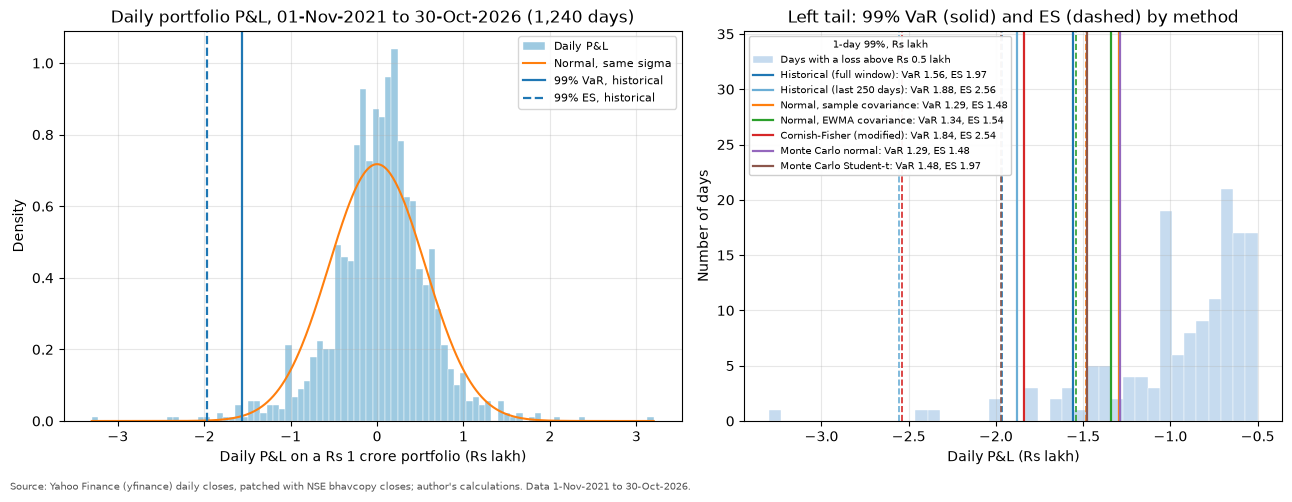

In [10]:
lines_99 = {m: (an.pick(od["summary"], m, 0.99, col="var_pct") / 100, an.pick(od["summary"], m, 0.99, col="es_pct") / 100)
            for m in dict.fromkeys(od["summary"]["method"])}
plots.plot_return_histogram(inp.port, V, lines_99); plt.show()

In [11]:
hs99, hs_es99 = an.pick(od["summary"], an.M_HS, 0.99), an.pick(od["summary"], an.M_HS, 0.99, col="es_inr")
n99 = an.pick(od["summary"], an.M_NS, 0.99)
cf99 = an.pick(od["summary"], an.M_CF, 0.99)
print(f"99% historical VaR Rs {hs99 / LAKH:.2f} lakh vs normal Rs {n99 / LAKH:.2f} lakh: the normal model is "
      f"{100 * (1 - n99 / hs99):.0f}% lower because the real tail is fatter.")
print(f"Cornish-Fisher moves the 99% VaR to Rs {cf99 / LAKH:.2f} lakh, close to the last-250-day historical "
      f"figure (Rs {an.pick(od['summary'], an.M_HS250, 0.99) / LAKH:.2f} lakh).")
full95 = one[(one["confidence"] == 0.95) & (one["method"] != an.M_HS250)]["var_inr"]
print(f"At 95% the full-window methods lie between Rs {an.inr(full95.min())} and Rs {an.inr(full95.max())}: "
      f"the methods differ mainly in the far tail.")
print(f"99% ES / VaR: historical {hs_es99 / hs99:.2f}, normal {an.pick(od['summary'], an.M_NS, 0.99, col='es_inr') / n99:.2f}")

99% historical VaR Rs 1.56 lakh vs normal Rs 1.29 lakh: the normal model is 17% lower because the real tail is fatter.
Cornish-Fisher moves the 99% VaR to Rs 1.84 lakh, close to the last-250-day historical figure (Rs 1.88 lakh).
At 95% the full-window methods lie between Rs 85,442 and Rs 94,932: the methods differ mainly in the far tail.
99% ES / VaR: historical 1.26, normal 1.15


**Reading the table.** At 95% the methods agree, because the middle of the distribution is close to normal. At 99% they split: the normal models (sample, EWMA, Monte Carlo normal) give ₹1.29 to 1.34 lakh, while historical simulation, Cornish-Fisher and the Student-t give ₹1.48 to 1.88 lakh. The Student-t has a lower 95% VaR than the normal: with the same variance, a fat-tailed distribution puts more mass in the centre and in the far tail and less in between.

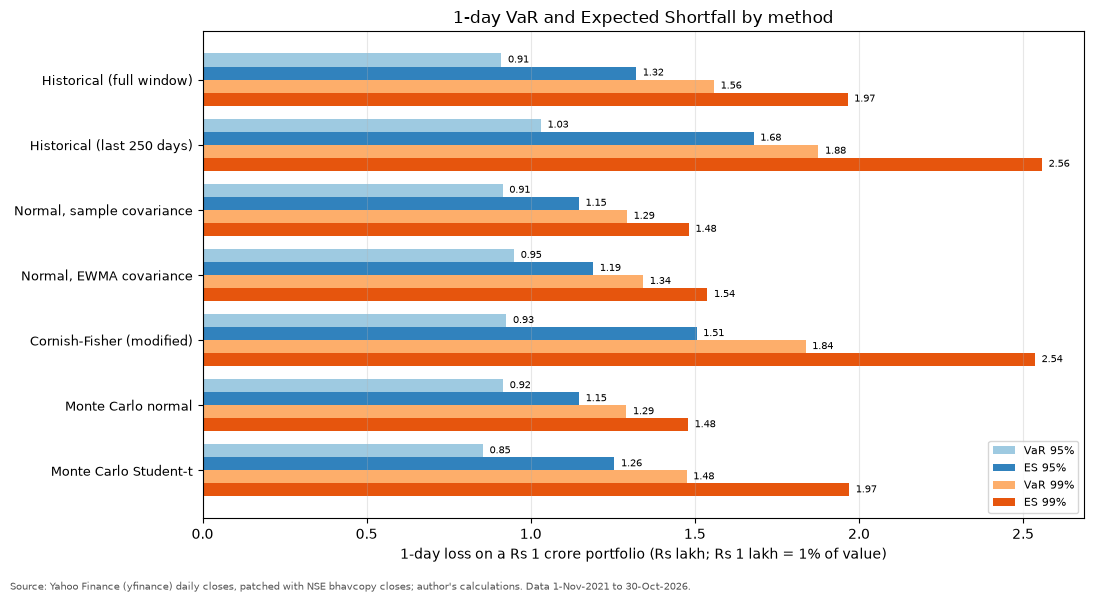

In [12]:
plots.plot_var_comparison(an.rounded_summary(od["summary"])); plt.show()

## 5. Monte Carlo convergence

How many simulations are enough? The line shows the 99% VaR from the first $n$ draws of the seed-42 run; the band is the 2.5% to 97.5% range of 200 independent runs of each size. The Monte Carlo error shrinks like $1/\sqrt{n}$. At 100,000 draws the 95% range of the normal estimate is about ±1% around the analytic value.

,n_sims,normal_nested_var_inr,normal_p2_5_inr,normal_p97_5_inr,t_nested_var_inr,t_p2_5_inr,t_p97_5_inr
0,100,141516.0,89428.0,155860.0,166948.0,86974.0,191850.0
1,200,153048.0,102361.0,148580.0,166948.0,97882.0,198494.0
2,500,139532.0,113942.0,144712.0,149653.0,114629.0,182562.0
3,1000,129550.0,115605.0,141227.0,128772.0,121311.0,175634.0
4,2000,126551.0,121752.0,138935.0,149483.0,130149.0,167395.0
5,5000,129188.0,123789.0,135935.0,133185.0,135865.0,157530.0
6,10000,129894.0,126015.0,133035.0,146849.0,138435.0,154024.0
7,20000,128700.0,126187.0,131926.0,145695.0,140962.0,152258.0
8,50000,128248.0,127483.0,131300.0,147523.0,142991.0,150393.0
9,100000,129136.0,128177.0,130598.0,147523.0,143949.0,149630.0


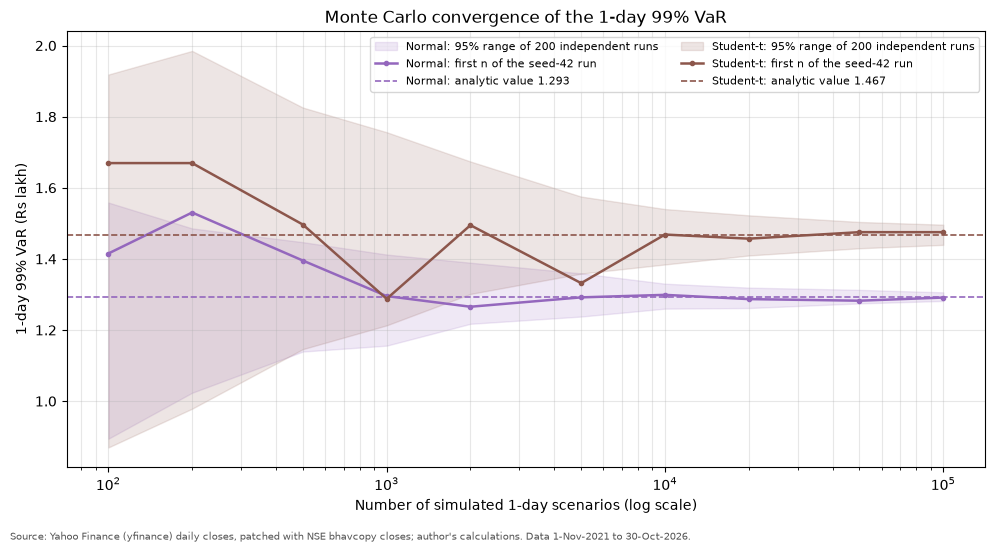

Normal, 100,000 draws: 95% of runs fall between Rs 128,177 and Rs 130,598 (analytic Rs 129,346)


In [13]:
conv = an.convergence(inp, od)
display(conv["table"])
plots.plot_mc_convergence(conv["nested"], conv["bands"], conv["analytic"], V); plt.show()
b = conv["bands"]["Normal"].loc[100_000]
print(f"Normal, 100,000 draws: 95% of runs fall between Rs {b['p2_5'] * V:,.0f} and Rs {b['p97_5'] * V:,.0f} "
      f"(analytic Rs {conv['analytic']['Normal'] * V:,.0f})")

## 6. Ten-day VaR: square-root-of-time vs direct estimates

Regulators and many risk reports use a 10-day horizon. The usual shortcut is $\text{VaR}_{10} = \sqrt{10}\,\text{VaR}_1$, which is exact only for independent, identically distributed, zero-mean normal returns. Direct estimates are computed for comparison:

* **Historical, direct:** overlapping 10-day returns of each ETF (positions held fixed for 10 days).
* **Monte Carlo, direct:** 10 independent daily draws per path, compounded per ETF.

The variance ratio $VR(10) = \text{Var}(r_{10}) / (10\,\text{Var}(r_1))$ shows whether returns trend (above 1) or mean-revert (below 1).

In [14]:
td = an.ten_day_var(inp, od)
summary = pd.concat([od["summary"], td], ignore_index=True)
ten = an.ten_day_comparison(summary)
vr10, eff10 = an.ten_day_diagnostics(inp)
display(ten)
display(vr10)
display(eff10)
base = inp.prices.index[inp.prices.index < inp.returns.index[0]][-1]
r10 = vm.overlapping_horizon_returns(inp.prices.loc[base:], cfg.HORIZON_DAYS) @ inp.w
s10, k10 = vm.sample_skew_kurt(r10.to_numpy())
q1 = (an.pick(summary, an.M_HS, 0.99) / V + inp.port.mean()) / inp.port.std()
q10 = (an.pick(summary, an.M_HS, 0.99, 10, "direct") / V + r10.mean()) / r10.std()
print(f"Excess kurtosis: 1-day {od['kurt']:.2f}, overlapping 10-day {k10:.2f}")
print(f"Historical 99% loss in standard deviations below the mean: 1-day {q1:.2f}, 10-day {q10:.2f} (normal: 2.33)")

,method,confidence,sqrt_time_var_inr,direct_var_inr,direct_over_sqrt_time,sqrt_time_es_inr,direct_es_inr
0,Historical (full window),0.95,287937,248203,0.862,417832,357560
1,Historical (full window),0.99,492856,415396,0.843,621532,481132
2,Monte Carlo normal,0.95,289578,285884,0.987,362843,356753
3,Monte Carlo normal,0.99,408365,401257,0.983,467789,458435
4,Monte Carlo Student-t,0.95,270190,283734,1.050,396881,369531
5,Monte Carlo Student-t,0.99,466510,418863,0.898,623054,506813


,series,vr10,lag1_autocorr
0,NIFTYBEES,1.083,0.026
1,JUNIORBEES,1.103,0.065
2,BANKBEES,1.153,0.028
3,MON100,1.140,0.027
4,GOLDBEES,0.814,-0.023
5,SETF10GILT,0.429,-0.280
6,Portfolio,1.042,0.020


,confidence,sqrt10_x_1day_inr,sqrt10_x_1day_demeaned_inr,direct_overlapping_inr,direct_demeaned_inr,drift_10d_inr,nonoverlap_min_inr,nonoverlap_max_inr,nonoverlap_obs
0,0.95,287937,301605,248203,290394,43223,211821,267588,124
1,0.99,492856,506524,415396,456908,43223,313239,473349,124


Excess kurtosis: 1-day 3.35, overlapping 10-day 0.91
Historical 99% loss in standard deviations below the mean: 1-day 2.88, 10-day 2.55 (normal: 2.33)


The direct historical 10-day 99% VaR is about 16% below the square-root figure. Two effects explain it. First, the sample has a positive drift (about ₹43,000 over 10 days at the sample mean), which the overlapping 10-day returns include. Second, 10-day returns are less fat-tailed than daily returns, because a sum of ten days is closer to normal, so the 99% loss sits fewer standard deviations below the mean. The portfolio's variance ratio is about 1.04, so the square-root rule gets the 10-day variance roughly right; what it overstates is the tail shape, by scaling up the fat-tailed one-day distribution. The gilt ETF is the exception among the holdings: its VR(10) of 0.43 and lag-1 autocorrelation of −0.28 show that its daily price noise from thin trading cancels out over 10 days. The 124 non-overlapping 10-day windows give anything from ₹3.1 lakh to ₹4.7 lakh depending on the start day, so the direct estimate is noisy. For a risk report the square-root figure is the more conservative and more stable choice here.

## 7. Where the risk comes from: component VaR

With the parametric normal model the VaR can be split exactly by ETF (Euler allocation):

$$\text{MVaR}_i = z_\alpha \frac{(\Sigma w)_i}{\sigma_p}, \qquad \text{CVaR}_i = w_i V\,\text{MVaR}_i, \qquad \sum_i \text{CVaR}_i = \text{VaR}_p$$

The standalone VaR of a position is $z_\alpha \sigma_i w_i V$; the sum of standalone VaRs minus the portfolio VaR is the diversification benefit.

,weight,standalone_var_inr,component_var_inr,contribution_pct,component_var_inr_ewma,contribution_pct_ewma
etf,,,,,,
NIFTYBEES,0.3,55678.4,49526.5,38.3,44304.6,33.0
JUNIORBEES,0.1,24296.7,19646.7,15.2,21318.7,15.9
BANKBEES,0.1,22892.4,18521.6,14.3,15521.2,11.6
MON100,0.1,31636.9,19333.2,14.9,20853.6,15.5
GOLDBEES,0.2,40165.1,16697.7,12.9,23720.3,17.7
SETF10GILT,0.2,19989.2,5619.8,4.3,8546.4,6.4


,covariance,undiversified_var_inr,portfolio_var_inr,diversification_benefit_inr,benefit_pct_of_undiversified
0,sample covariance,194659.0,129346.0,65313.0,33.6
1,EWMA covariance,187970.0,134265.0,53706.0,28.6


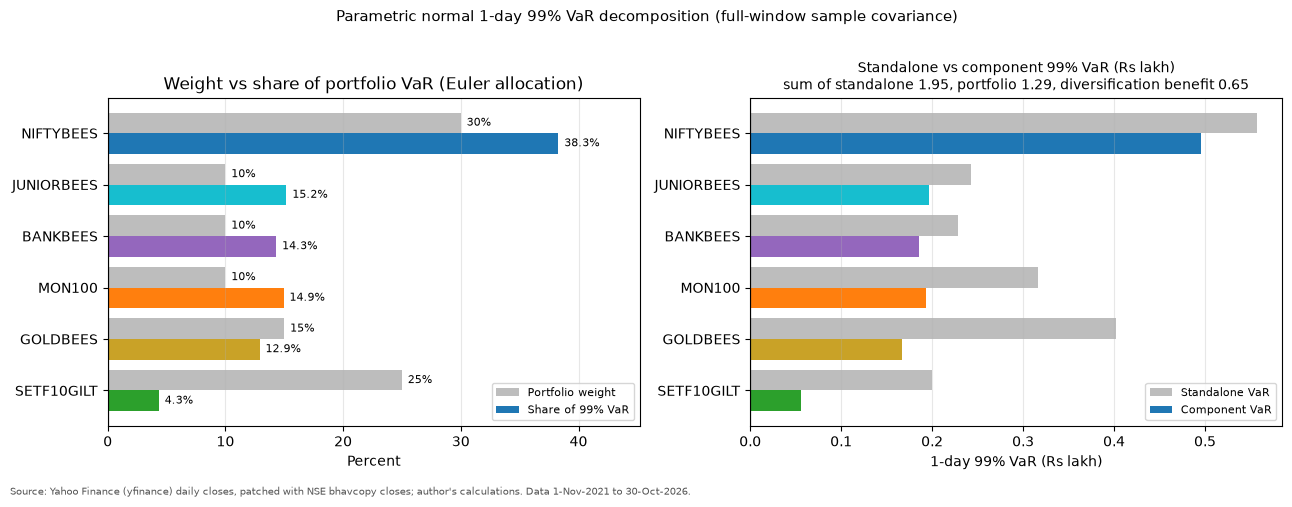

In [15]:
dec = an.decomposition(inp, od)
div = an.diversification(dec, od)
display(dec[["weight", "standalone_var_inr", "component_var_inr", "contribution_pct", "component_var_inr_ewma",
             "contribution_pct_ewma"]].round(1))
display(div)
plots.plot_component_var(dec, float(div.loc[0, "portfolio_var_inr"])); plt.show()

Indian equities (NIFTYBEES, JUNIORBEES, BANKBEES) are 50% of the money but about 68% of the risk. The gilt ETF is 25% of the money and about 4% of the risk. Gold is 15% of the money and about 13% of the risk with the full-window covariance, but about 18% with the EWMA covariance, because gold was far more volatile in 2026 than before. Diversification cuts the 99% VaR by a third compared with adding up the six standalone VaRs.

## 8. Backtest: would the models have worked?

Each trading day from 3-Nov-2022 to 30-Oct-2026 (990 days), every model is re-estimated on the previous 250 days only and forecasts the next day's 95% and 99% VaR. An **exception** is a day whose loss is larger than the forecast. The models are historical simulation, normal with the sample or EWMA volatility, Student-t with EWMA volatility (degrees of freedom refitted daily) and **filtered historical simulation** (FHS: historical quantiles of returns divided by their EWMA volatility, rescaled by today's volatility).

**Kupiec proportion-of-failures test** (is the exception rate right?), with $x$ exceptions in $n$ days:

$$LR_{pof} = -2\ln\frac{(1-p)^{n-x}p^x}{(1-\hat p)^{n-x}\hat p^x} \sim \chi^2_1, \qquad \hat p = x/n$$

**Christoffersen independence test** (do exceptions cluster?): with $n_{ij}$ the number of days in state $j$ after a day in state $i$ (1 = exception), compare $\pi_{01} = n_{01}/(n_{00}+n_{01})$ and $\pi_{11} = n_{11}/(n_{10}+n_{11})$ with a single rate; $LR_{ind} \sim \chi^2_1$. **Conditional coverage** tests both at once on the day-to-day transitions, $LR_{cc} = LR_{pof} + LR_{ind} \sim \chi^2_2$. A model is rejected when the p-value is below 5%.

**Basel traffic light** (99% VaR, last 250 days): 0 to 4 exceptions green, 5 to 9 yellow, 10 or more red.

,model,confidence,expected,exceptions,rate_pct,p_pof,n11,p_ind,p_cc,pof_verdict,cc_verdict,exceptions_last250,p_pof_last250,basel_zone_last250
0,Historical simulation,0.95,49.5,56,5.66,0.3528,5,0.3106,0.3857,accept,accept,23,0.0061,
1,Historical simulation,0.99,9.9,14,1.41,0.2176,1,0.1885,0.1962,accept,accept,4,0.3805,green
2,Normal (sample sigma),0.95,49.5,43,4.34,0.3327,3,0.4235,0.4572,accept,accept,13,0.8853,
3,Normal (sample sigma),0.99,9.9,18,1.82,0.0203,1,0.3324,0.0419,reject,reject,7,0.0190,yellow
4,Normal (EWMA sigma),0.95,49.5,53,5.35,0.6137,4,0.4906,0.6915,accept,accept,16,0.3294,
5,Normal (EWMA sigma),0.99,9.9,28,2.83,0.0000,1,0.8175,0.0000,reject,reject,10,0.0003,red
6,Student-t (EWMA sigma),0.95,49.5,59,5.96,0.1782,5,0.4265,0.2915,accept,accept,17,0.2146,
7,Student-t (EWMA sigma),0.99,9.9,20,2.02,0.0046,1,0.4179,0.0128,reject,reject,7,0.0190,yellow
8,Filtered HS (EWMA),0.95,49.5,51,5.15,0.8277,4,0.4045,0.6888,accept,accept,17,0.2146,
9,Filtered HS (EWMA),0.99,9.9,15,1.52,0.1300,1,0.2208,0.1495,accept,accept,5,0.1619,yellow


EWMA-standardised returns, out of sample: variance 1.083 (1 if EWMA were right), excess kurtosis 1.54, share below -2.326: 2.83% (normal: 1%)


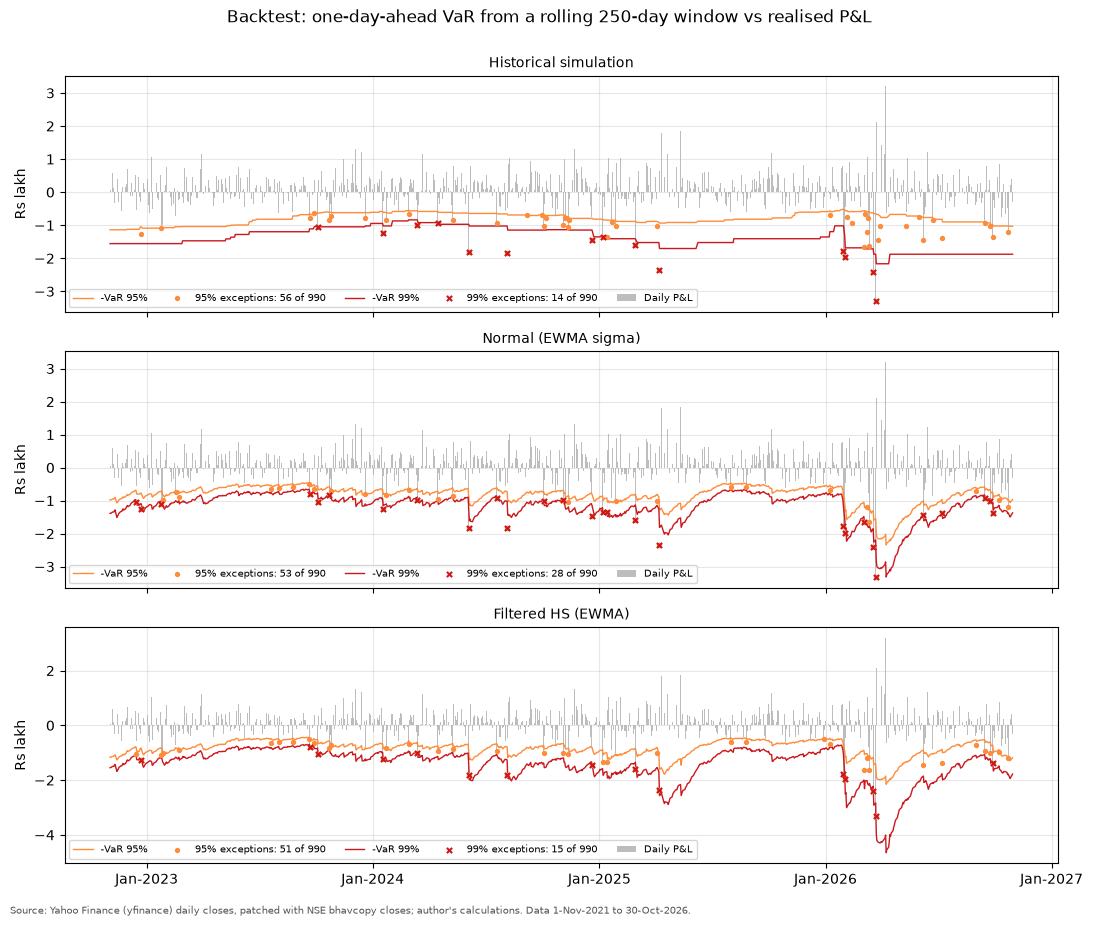

In [16]:
fc, bts = an.run_backtest(inp)
cols = ["model", "confidence", "expected", "exceptions", "rate_pct", "p_pof", "n11", "p_ind", "p_cc", "pof_verdict",
        "cc_verdict", "exceptions_last250", "p_pof_last250", "basel_zone_last250"]
display(bts[cols])
resid = bt.residual_diagnostics(fc)
print(f"EWMA-standardised returns, out of sample: variance {resid['variance']:.3f} (1 if EWMA were right), "
      f"excess kurtosis {resid['excess_kurtosis']:.2f}, share below -2.326: {100 * resid['share_below_-2.326']:.2f}% (normal: 1%)")
plots.plot_backtest(fc, V, {k: bt.MODELS[k] for k in ["hs", "n_ewma", "fhs"]}); plt.show()

**Verdict.**

* **Historical simulation and filtered historical simulation pass** the Kupiec, independence and conditional-coverage tests at both levels over the 990 days. In the last 250 days historical simulation is in the green zone (4 exceptions at 99%) and FHS in the yellow zone (5).
* **Normal with EWMA volatility fails at 99%** (28 exceptions against 9.9 expected; red zone in the last 250 days). EWMA tracks volatility well, as its 95% results show, but scaling a normal quantile by it misses the fat tails: after dividing by the EWMA volatility the returns still have excess kurtosis of about 1.5 and a variance about 8% above 1.
* **Normal with the sample volatility and the Student-t with EWMA volatility also fail Kupiec at 99%** (18 and 20 exceptions) and sit in the yellow zone.
* No model shows significant clustering (all independence p-values above 5%), but the last 250 days were hard for everyone: historical simulation had 23 exceptions at 95% against 12.5 expected (Kupiec p = 0.006 on that year alone), because the 2026 shocks arrived faster than a 250-day window adapts.

The next-day forecasts (for Monday 2-Nov-2026) from the same five models:

In [17]:
nxt = bt.next_day_forecasts(inp.port, inp.returns, inp.w, cfg.RECENT_WINDOW, cfg.CONFIDENCE_LEVELS, cfg.EWMA_LAMBDA, V)
display(nxt)
print(f"EWMA volatility forecast {100 * nxt.attrs['sigma_ewma_next']:.3f}% per day; Student-t nu {nxt.attrs['nu_next']:.2f}")

,model,key,var95_inr,var95_pct,var99_inr,var99_pct
0,Historical simulation,hs,103107.0,1.0311,187665.0,1.8766
1,Normal (sample sigma),n_sample,113680.0,1.1368,160780.0,1.6078
2,Normal (EWMA sigma),n_ewma,94932.0,0.9493,134265.0,1.3426
3,Student-t (EWMA sigma),t_ewma,91217.0,0.9122,148745.0,1.4874
4,Filtered HS (EWMA),fhs,115782.0,1.1578,174023.0,1.7402


EWMA volatility forecast 0.577% per day; Student-t nu 5.70


## 9. Stress tests

VaR says nothing about how bad the worst days can be. Two kinds of stress test are applied to today's positions:

* **Historical:** the five worst days for the current weights in the window, with the event behind each (sources in the README).
* **Hypothetical:** instantaneous shocks. The MON100 shock combines a 15% fall in the Nasdaq-100 with a 3% rise in the rupee: $(1-0.15)(1-0.03)-1 = -17.55\%$ in rupees.

In [18]:
worst, hyp = an.run_stress(inp, od)
stress = an.stress_table(worst, hyp)
display(stress.drop(columns=["description"]))
for _, x in stress[stress["type"] == "historical"].iterrows():
    print(f"{x['date']}: {x['description']}")

,type,scenario,date,NIFTYBEES_move_pct,JUNIORBEES_move_pct,BANKBEES_move_pct,MON100_move_pct,GOLDBEES_move_pct,SETF10GILT_move_pct,total_pnl_inr,total_pnl_pct,multiple_of_1d_var99
0,historical,Worst day 2026-03-23,2026-03-23,-2.64,-3.83,-3.48,-3.00,-8.54,-0.79,-330147.0,-3.301,2.12
1,historical,Worst day 2026-03-19,2026-03-19,-2.71,-2.60,-3.12,-0.93,-5.15,-0.60,-240048.0,-2.400,1.54
2,historical,Worst day 2025-04-07,2025-04-07,-3.13,-2.81,-2.93,-6.59,-1.55,0.21,-235211.0,-2.352,1.51
3,historical,Worst day 2022-02-24,2022-02-24,-3.62,-5.26,-4.68,-4.10,3.55,-0.27,-202282.0,-2.023,1.30
4,historical,Worst day 2026-02-01,2026-02-01,-1.51,-1.57,-2.02,-0.65,-6.72,-0.35,-197119.0,-1.971,1.26
5,hypothetical,Indian equity -10%,,-10.00,-10.00,-10.00,0.00,0.00,0.00,-500000.0,-5.000,3.21
6,hypothetical,Nasdaq-100 -15% and INR +3%,,0.00,0.00,0.00,-17.55,0.00,0.00,-175500.0,-1.755,1.13
7,hypothetical,Gold +5%,,0.00,0.00,0.00,0.00,5.00,0.00,75000.0,0.750,-0.48
8,hypothetical,Bonds -2% (yield spike),,0.00,0.00,0.00,0.00,0.00,-2.00,-50000.0,-0.500,0.32
9,hypothetical,Combined (all four),,-10.00,-10.00,-10.00,-17.55,5.00,-2.00,-650500.0,-6.505,4.17


2026-03-23: US-Iran war: crude oil above $105 and no clarity on the Strait of Hormuz; NIFTY 50 -2.6% to 22,512.65 and gold and silver fell about 10% (Livemint, Financial Express)
2026-03-19: Crude-oil spike, hawkish US Fed and an HDFC Bank sell-off after its part-time chairman resigned; NIFTY 50 -3.26% to 23,002.15, its worst day since 4-Jun-2024 (Livemint, CNBC-TV18)
2025-04-07: Global sell-off after the US reciprocal tariffs; NIFTY 50 -3.24% to 22,161.60 (Times of India)
2022-02-24: Russia invaded Ukraine; NIFTY 50 -4.78% to 16,247.95 while gold rose (The Hindu, Times of India)
2026-02-01: Sunday Union Budget session: higher STT on futures and options (NIFTY 50 -1.96% to 24,825.45) and gold ETFs fell further after the 30-Jan precious-metals crash (The Hindu, Economic Times)


The worst day, 23-Mar-2026, lost ₹3.30 lakh, 2.1 times the 99% historical VaR, because gold fell 8.5% on the same day as equities, so the usual hedge failed. On 24-Feb-2022 (Russia invades Ukraine) gold rose 3.6% and cushioned the equity loss. The combined hypothetical scenario costs ₹6.5 lakh, about 4 times the 99% VaR.

## 10. Sensitivity checks

**ETF price vs index.** An ETF's closing price can sit away from the value of its holdings on a stress day. On 4-Jun-2024 (general election results) NIFTYBEES closed 2.97% lower while the NIFTY 50 fell 5.93% (both confirmed from the NSE bhavcopy); the gap closed the next day. Replacing NIFTYBEES returns with NIFTY 50 index returns shows how much this smoothing hides.

In [19]:
sens = an.index_sensitivity(inp)
display(sens)
nsei = dp.read_yahoo(cfg.CALENDAR_TICKER)["Close"]
jun = pd.DataFrame({"NIFTYBEES_pct": 100 * inp.returns["NIFTYBEES.NS"], "NIFTY50_pct": 100 * nsei.pct_change()}).loc["2024-06-03":"2024-06-05"]
display(jun.round(2))
print(f"Daily tracking difference (ETF - index): sd {sens.attrs['tracking_sd_daily_pct']:.2f}%, "
      f"lag-1 autocorrelation {sens.attrs['tracking_autocorr']:.2f} (the gap reverses the next day)")

,confidence,var_etf_inr,var_index_inr,es_etf_inr,es_index_inr,days_swapped
0,0.95,91054,94050,132130,136688,1235
1,0.99,155855,157827,196546,210067,1235


,NIFTYBEES_pct,NIFTY50_pct
Date,,
2024-06-03,2.78,3.25
2024-06-04,-2.97,-5.93
2024-06-05,0.33,3.36


Daily tracking difference (ETF - index): sd 0.19%, lag-1 autocorrelation -0.37 (the gap reverses the next day)


**Two ES estimators.** The tail-mean estimator used throughout averages every return at or below the VaR quantile. The Acerbi-Tasche estimator averages exactly $np$ worst returns (the last one with a fractional weight). They agree when $np$ is a whole number and differ by less than 1% for the full window at 99%; on 250 days the gap is larger because the tail holds only 2.5 to 3 days.

In [20]:
display(an.es_estimators(inp))

,window,confidence,observations,n_times_p,tail_days_averaged,var_inr,es_tail_mean_inr,es_acerbi_tasche_inr,difference_pct
0,full window,0.95,1240,62.0,62,91054,132130,132130,-0.00
1,full window,0.99,1240,12.4,13,155855,196546,198387,0.94
2,last 250 days,0.95,250,12.5,13,103107,167926,170496,1.53
3,last 250 days,0.99,250,2.5,3,187665,255772,267502,4.59


## 11. Validation checks

The checks below confirm that the code does what the method says. They cover the data (cleaned prices equal every NSE close fetched, every large move explained, the bond screen), the historical quantiles (equal to `numpy` and `pandas`), Monte Carlo against closed forms (VaR within 2%, ES within 3 Monte Carlo standard errors), the ES formulas (closed form against numerical integration), the decomposition (components add up to the total), the matrices, and the backtest statistics (textbook Kupiec acceptance regions, the conditional-coverage identity, the Basel zones from the binomial rule, and a no-look-ahead test).

In [21]:
checks = an.validation_checks(inp, od, summary, dec, fc, eff10)
for _, c in checks.iterrows():
    print(f"{c['result']}: {c['check']} | {c['detail']}")
n_fail = int((checks["result"] == "FAIL").sum())
print(f"\nVALIDATION: {len(checks) - n_fail} PASS, {n_fail} FAIL")
assert n_fail == 0, "a validation check failed"

PASS: Weights sum to 1 | sum = 1.000000000000
PASS: No missing returns in the window | 1240 days x 6 ETFs
PASS: Cleaned closes equal every NSE bhavcopy close fetched | 453 ETF-days on 76 dates; Yahoo as downloaded matched 399
PASS: Every large one-day move is confirmed by NSE or removed by a data fix | 35 moves screened: 32 genuine, 3 artefacts of bad prints or missing sessions
PASS: Bond ETF screen selects the gilt ETF held in the portfolio | selected ['SETF10GILT.NS']; 1 of 9 candidates eligible
PASS: Historical VaR 95% (full window) equals the empirical quantile | own 91,053.63 vs numpy 91,053.63 vs pandas 91,053.63 Rs
PASS: Historical VaR 95% (last 250 days) equals the empirical quantile | own 103,106.97 vs numpy 103,106.97 vs pandas 103,106.97 Rs
PASS: Historical VaR 99% (full window) equals the empirical quantile | own 155,854.70 vs numpy 155,854.70 vs pandas 155,854.70 Rs
PASS: Historical VaR 99% (last 250 days) equals the empirical quantile | own 187,664.61 vs numpy 187,664.61 

Finally, the notebook's results are compared with the files that `src/run_all.py` wrote to `outputs/`. Both use the same functions and seeds, so they must be identical.

In [22]:
def same_as_saved(df: pd.DataFrame, file: str) -> bool:
    saved = pd.read_csv(cfg.OUTPUTS / file)
    df = df.reset_index(drop=True)
    ok = list(saved.columns) == list(df.columns) and len(saved) == len(df)
    if ok:
        for col in saved.columns:
            if pd.api.types.is_numeric_dtype(saved[col]) and pd.api.types.is_numeric_dtype(df[col]):
                ok &= bool(np.allclose(saved[col].to_numpy(float), df[col].to_numpy(float), rtol=0, atol=1e-6,
                                       equal_nan=True))
            else:
                ok &= bool((saved[col].fillna("").astype(str) == df[col].fillna("").astype(str)).all())
    print(f"{'PASS' if ok else 'FAIL'}: notebook result equals outputs/{file}")
    return ok


results = [
    same_as_saved(an.rounded_summary(summary), "var_summary.csv"),
    same_as_saved(bts, "backtest_summary.csv"),
    same_as_saved(dec.round(6).reset_index(), "component_var.csv"),
    same_as_saved(div, "diversification.csv"),
    same_as_saved(stress, "stress_tests.csv"),
    same_as_saved(conv["table"], "mc_convergence.csv"),
    same_as_saved(ten, "ten_day_comparison.csv"),
    same_as_saved(nxt, "next_day_var.csv"),
    same_as_saved(checks, "validation_checks.csv"),
]
assert all(results), "notebook and outputs/ differ: re-run python src/run_all.py"

PASS: notebook result equals outputs/var_summary.csv
PASS: notebook result equals outputs/backtest_summary.csv
PASS: notebook result equals outputs/component_var.csv
PASS: notebook result equals outputs/diversification.csv
PASS: notebook result equals outputs/stress_tests.csv
PASS: notebook result equals outputs/mc_convergence.csv
PASS: notebook result equals outputs/ten_day_comparison.csv
PASS: notebook result equals outputs/next_day_var.csv
PASS: notebook result equals outputs/validation_checks.csv


## Summary

* On 30-Oct-2026 the ₹1 crore portfolio has a one-day 99% VaR of ₹1.29 to 1.34 lakh under the normal models and ₹1.48 to 1.88 lakh under the methods that allow fat tails (historical ₹1.56 lakh). The 99% Expected Shortfall runs from ₹1.48 lakh (normal) to about ₹2.55 lakh (Cornish-Fisher and the last 250 days).
* Historical simulation and filtered historical simulation pass the backtest; normal VaR at 99% does not.
* Indian equities carry about two thirds of the risk; the gilt ETF and gold diversify, but gold fell with equities on the worst day of the sample.

Educational project, not investment advice.